# 全部合格 ETF：PCA 统计套利

读取数据 → 按日期划分 → 滚动 PCA 与 AR(1) → 信号转仓位 → 保存 CSV → 读取回测。先用一组固定参数，不做网格搜索。模型使用对数收益，回测时用 `expm1` 还原。

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

split_date = pd.Timestamp('2025-08-22')
window = 100
k = 3
s_open = 1.25
s_close = 0.5
fee = 0.0005
Path('outputs').mkdir(exist_ok=True)

## 1. 读取数据，按训练期筛选 ETF

日期不晚于 split_date 的数据为训练集，其后为测试集。使用训练首日已有、训练数据完整、价格为正且收益波动非零的股票型 ETF。

In [2]:
columns = ['date', 'code', 'name', 'fund_type', 'log_ret_1d', 'close_hfq']
data = pd.read_csv('data/etf.csv', usecols=columns, dtype={'code': str}, parse_dates=['date'])
train = data.loc[data['date'] <= split_date].copy()
candidates = train.loc[
    train['date'].eq(train['date'].min()) & train['fund_type'].eq('股票型'), ['code', 'name']
].sort_values('code')
# 数据转成shape(n, c)
train_returns = train.pivot(index='date', columns='code', values='log_ret_1d')[candidates['code']]
train_prices = train.pivot(index='date', columns='code', values='close_hfq')[candidates['code']]
# 数据过滤
eligible = (np.isfinite(train_returns).all() & np.isfinite(train_prices).all()
            & train_prices.gt(0).all() & train_returns.std().gt(0).reindex(train_returns.columns))
codes = eligible.index[eligible].tolist()
df_selected = candidates.loc[candidates['code'].isin(codes)].copy()
# 保存本次实际使用的 ETF 名单
df_selected.to_csv('outputs/pca_etfs.csv', index=False)
train_returns = train_returns[codes]
print(f'使用 {len(codes)} 只 ETF，训练 {len(train_returns)} 个交易日')
df_selected.head()

使用 440 只 ETF，训练 623 个交易日


,code,name
3,159601,华夏MSCI中国A50互联互通ETF
4,159602,南方MSCI中国A50互联互通ETF
6,159606,易方达中证500质量成长ETF
8,159608,广发中证稀有金属ETF
9,159703,天弘中证新材料主题ETF


## 2. 训练期滚动 PCA 与 AR(1)

每次使用截至当天的 window 日对数收益。标准化后去掉前 k 个主成分，累计残差后拟合 AR(1)，计算 s 和半衰期。

In [3]:
returns = train_returns
scores = pd.DataFrame(np.nan, index=returns.index, columns=returns.columns)
half_lives, vols = scores.copy(), scores.copy()
loadings = {}
for i in range(window - 1, len(returns)):
    sample = returns.iloc[i-window+1:i+1].to_numpy() # shape(w, n),n是ETF数量
    std = sample.std(axis=0)# 对windows内取波动率
    standardized = (sample - sample.mean(axis=0)) / std # 归一化，方便用主成分
    _, _, vt = np.linalg.svd(standardized, full_matrices=False) # 得到的是vt矩阵，shape(n, n)
    loading = vt[:k] # k是主成分数量 shape(k, n)
    residual = standardized - (standardized @ loading.T) @ loading # 先将原来的n个etf收益转换为k个主成分因子，然后再利用主成分重构原始数据，最后计算残差，shape(w,n)
    # 这里的残差是剥除掉波动率最高的k个主成分因子后的残差，得到的是每个etf的各自的特点
    X = residual.cumsum(axis=0) # 按照window内对残差求和，shape(n)
    lag, current = X[:-1], X[1:] # 取前w-1个etf的残差，当前etf的残差
    centered = lag - lag.mean(axis=0)
    # 拟合ar(1)方程 x_t = a + b * x_t-1 + e_t
    b = (centered * (current - current.mean(axis=0))).sum(axis=0) / (centered**2).sum(axis=0) # 直接计算一阶滞后相关系数
    a = current.mean(axis=0) - b * lag.mean(axis=0)
    innovation = current - a - b * lag
    b = np.where((b > 0) & (b < 1), b, np.nan)
    m = a / (1 - b) # 假设x_t-1的期望= x_t的期望，也就是期望不变的前提下
    sigma_eq = innovation.std(axis=0, ddof=2) / np.sqrt(1 - b**2) # 当前累计残差偏离均值多少个标准差
    date = returns.index[i]
    scores.loc[date] = (X[-1] - m) / sigma_eq # 计算z-score
    half_lives.loc[date] = -np.log(2) / np.log(b)
    vols.loc[date] = std
    loadings[date] = loading

scores


code,159601,159602,159606,159608,159703,159706,159707,159708,159709,159712,...,588150,588180,588280,588300,588310,588330,588360,588380,588390,588400
date,,,,,,,,,,,,,,,,,,,,,
2023-02-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2023-02-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2023-02-06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2023-02-07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2023-02-08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-08-18,0.970446,1.122509,-0.833995,1.301546,0.938657,1.356655,0.008618,0.368264,0.766612,-1.437363,...,-0.198415,-0.295754,-0.153820,1.567451,1.791019,1.629723,1.519172,1.589525,1.383813,1.700997
2025-08-19,0.854751,1.053809,-0.560435,1.377133,0.759431,1.578292,0.186503,0.352221,1.346384,-1.544392,...,-0.380816,-0.603606,-0.576895,1.584719,1.757914,1.654703,1.648426,1.577428,1.470522,1.814646
2025-08-20,0.862437,0.876634,-0.603197,1.215415,0.484273,1.572232,-0.032219,0.333228,1.051882,-1.488653,...,0.151621,-0.061344,-0.063857,1.359717,1.595540,1.437133,1.419792,1.453579,1.278413,1.522977


In [4]:
scores

code,159601,159602,159606,159608,159703,159706,159707,159708,159709,159712,...,588150,588180,588280,588300,588310,588330,588360,588380,588390,588400
date,,,,,,,,,,,,,,,,,,,,,
2023-02-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2023-02-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2023-02-06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2023-02-07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2023-02-08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-08-18,0.970446,1.122509,-0.833995,1.301546,0.938657,1.356655,0.008618,0.368264,0.766612,-1.437363,...,-0.198415,-0.295754,-0.153820,1.567451,1.791019,1.629723,1.519172,1.589525,1.383813,1.700997
2025-08-19,0.854751,1.053809,-0.560435,1.377133,0.759431,1.578292,0.186503,0.352221,1.346384,-1.544392,...,-0.380816,-0.603606,-0.576895,1.584719,1.757914,1.654703,1.648426,1.577428,1.470522,1.814646
2025-08-20,0.862437,0.876634,-0.603197,1.215415,0.484273,1.572232,-0.032219,0.333228,1.051882,-1.488653,...,0.151621,-0.061344,-0.063857,1.359717,1.595540,1.437133,1.419792,1.453579,1.278413,1.522977


In [5]:
loadings

{Timestamp('2023-06-29 00:00:00'): array([[-0.06084743, -0.0605285 , -0.05821496, ..., -0.05464824,
         -0.05687539, -0.05599986],
        [-0.02946456, -0.02937215, -0.03080879, ..., -0.01789795,
         -0.0159561 , -0.01595964],
        [-0.03763973, -0.04190106,  0.01652012, ...,  0.06933237,
          0.06242625,  0.06791982]]),
 Timestamp('2023-06-30 00:00:00'): array([[ 0.06055231,  0.06038211,  0.05817431, ...,  0.05467638,
          0.05686536,  0.05600545],
        [-0.02855691, -0.02876048, -0.03044179, ..., -0.0179261 ,
         -0.01619809, -0.01612565],
        [-0.03800284, -0.04196956,  0.01654832, ...,  0.06917136,
          0.06228474,  0.06769008]]),
 Timestamp('2023-07-03 00:00:00'): array([[ 0.06055705,  0.06032489,  0.05784938, ...,  0.05476753,
          0.05675865,  0.05601425],
        [-0.02808916, -0.0284848 , -0.03016783, ..., -0.01855476,
         -0.01661877, -0.01657722],
        [-0.03826426, -0.04244145,  0.01823088, ...,  0.06792013,
          0.

## 3. 训练信号转为权重

半衰期 5～60 日允许开仓，s 低于负开仓线做多，高于正开仓线做空；进入平仓带或模型失效时退出。减去主成分投影，再除以波动率，总绝对权重归一为 1。

In [6]:
# 先建日期 × ETF 的权重表，初始全部空仓
weights = pd.DataFrame(0.0, index=scores.index, columns=scores.columns)
# 记录每只 ETF 的残差交易方向：1 做多，-1 做空，0 空仓
direction = np.zeros(len(scores.columns))
# 按日期更新方向，未触发开平仓条件时保留原方向
for date, loading in loadings.items():
    # 取当天每只 ETF 的 s 信号
    s = scores.loc[date].to_numpy()
    # 取当天估计的均值回归半衰期，单位是交易日
    hl = half_lives.loc[date].to_numpy()
    # 只使用有效信号，并要求半衰期在 5～60 日之间
    valid = np.isfinite(s) & (hl >= 5) & (hl <= 60)
    # 进入平仓带或信号无效时，把主动方向清零
    direction = np.where((np.abs(s) < s_close) | ~valid, 0, direction)
    # 残差偏低时做多，等它向均值回归
    direction = np.where(valid & (s < -s_open), 1, direction)
    # 残差偏高时做空，等它向均值回归
    direction = np.where(valid & (s > s_open), -1, direction)
    # 扣掉方向在 PCA 因子上的投影，再除以波动率，转成 ETF 对冲权重，这里主要是计算仓位强度
    weight = (direction - loading.T @ (loading @ direction)) / vols.loc[date].to_numpy() # loading.shape = (k, n), direction.shape = (n,)
    # 按绝对权重之和归一化；没有仓位时保持为 0，避免除以 0
    weights.loc[date] = weight / max(np.abs(weight).sum(), 1e-12)

# 保留训练权重，后面测试时会重新使用 weights 变量
# 前 window-1 日还没有完整窗口，不保存这些预热行；有效的零仓位仍保留
df_train_weights = weights.iloc[window-1:].copy()
# 把 s 信号保存到 CSV，方便查看每一天的计算结果
scores.iloc[window-1:].to_csv("outputs/pca_train_scores.csv", index_label="date")
# 保存训练目标权重，回测时再从这个 CSV 读取
df_train_weights.to_csv("outputs/pca_train_weights.csv", index_label="date")
df_train_weights.head()



code,159601,159602,159606,159608,159703,159706,159707,159708,159709,159712,...,588150,588180,588280,588300,588310,588330,588360,588380,588390,588400
date,,,,,,,,,,,,,,,,,,,,,
2023-06-29,-0.012358,-0.012489,-0.000750,-0.000573,-0.000886,-0.000468,0.000354,0.000432,-0.000062,-0.008547,...,-0.000259,-0.000240,-0.000272,-0.001028,-0.001076,-0.000953,-0.000897,-0.000979,-0.000905,-0.000945
2023-06-30,-0.012112,-0.012224,-0.000846,-0.000635,-0.000950,-0.000538,0.000325,0.000386,-0.000022,-0.008354,...,-0.000216,-0.000196,-0.000228,-0.001062,-0.001126,-0.000984,-0.000925,-0.001012,-0.000940,-0.000976
2023-07-03,-0.011663,-0.011726,-0.000736,-0.000557,-0.000862,-0.000445,0.000325,0.000401,-0.000032,-0.008070,...,-0.000206,-0.000187,-0.000215,-0.000949,-0.001013,-0.000883,-0.000832,-0.000901,-0.000840,-0.000869
2023-07-04,0.000013,-0.012731,-0.000353,-0.000376,-0.000613,-0.000072,0.000328,0.000482,0.000370,-0.008691,...,0.000250,0.000266,0.000245,-0.000420,-0.000589,-0.000357,-0.000308,-0.000399,-0.000347,-0.000363
2023-07-05,0.000144,-0.012237,-0.000010,-0.000161,-0.000285,0.000191,0.000265,0.000440,0.000479,-0.008458,...,0.000416,0.000426,0.000416,-0.000004,-0.000186,0.000040,0.000071,-0.000003,0.000034,0.000024


## 4. 读取训练信号并回测

`log_ret_1d[t] = log(close[t]/close[t-1])`。昨日权重 shift 一次后乘当行还原收益，初始空仓、净值 1，固定初始资金调仓、加法累计净值。等权基准使用相同 ETF、相同日期，每日等权再平衡且不扣费用。

保留现有的理想化假设：信号日能以同一收盘价即时成交；实际收盘后才形成信号时，不能保证此价格。允许模拟卖空，按目标权重变化估算换手并扣交易费，不计借券费；不模拟券源、保证金和现金利息。

累计换手是各 ETF 目标权重变化绝对值的累计和，包含首次建仓；估算交易费用为 `turnover × fee`。不计价格变化引起的额外再平衡换手。

In [7]:
# 读取之前保存的信号权重，date 作为日期索引
signal_weights = pd.read_csv("outputs/pca_train_weights.csv", parse_dates=["date"]).set_index("date")
returns = train_returns
# 第一段完整窗口结束后，从下一个交易日开始计算收益
start = train_returns.index[window]
# 把昨日信号移到今天，用昨日目标权重计算今天收盘到收盘的收益
weights = signal_weights.shift(1).loc[start:].copy()
# 对数收益用 expm1 还原成简单收益，再与权重相乘
asset_returns = np.expm1(returns.loc[weights.index])
# 用各 ETF 目标权重变化的绝对值之和估算换手
# 第一行 diff 为 NaN，填入当天权重，计入从空仓开始的建仓费用
turnover = weights.diff().fillna(weights).abs().sum(axis=1)
# 找到每段收益的起始日期，用于在曲线前面补初始净值 1
return_start = returns.index.to_series().shift(1).loc[weights.index]
# 每行存当天的收益、换手和费用
result = pd.DataFrame(index=weights.index)
# 对所有 ETF 的权重 × 当天简单收益求和，得到扣费前组合收益
result['gross_ret'] = (weights * asset_returns).sum(axis=1)
# 简化换手按目标权重变化估算，包含做多和做空两边的变化
result['turnover'] = turnover
# 交易费用 = 换手 × 单边费率，不计算借券费
result['trade_cost'] = turnover * fee
# 从组合收益中减去当天交易费用
result['strategy_ret'] = result['gross_ret'] - result['trade_cost']
# 按固定初始资金加法累计，初始净值为 1
result['net_value'] = 1 + result['strategy_ret'].cumsum()
# 两条曲线都补上初始值 1；等权基准每天对全部入选 ETF 等权配置，不扣费
curves = pd.DataFrame({
    'PCA strategy': np.r_[1.0, result['net_value']],
    'Equal weight (no costs)': np.r_[1.0, 1 + asset_returns.mean(axis=1).cumsum()]
}, index=pd.DatetimeIndex([return_start.iloc[0], *weights.index]))
ret = result['strategy_ret']
nav = curves['PCA strategy']
# 计算累计收益、日收益年化夏普、最大回撤以及累计换手和费用
metrics = pd.Series({
    '累计收益': nav.iloc[-1] - 1,
    '年化夏普': ret.mean() / ret.std(ddof=0) * np.sqrt(252) if ret.std(ddof=0) > 0 else np.nan,
    '最大回撤': (nav / nav.cummax() - 1).min(),
    '累计换手': turnover.sum(),
    '交易费用': result['trade_cost'].sum()
})

# 保留训练结果，避免后面的测试计算覆盖它们
df_train_backtest = result.copy()
train_curves = curves.copy()
train_metrics = metrics.copy()
# 保存训练期逐日回测明细
df_train_backtest.to_csv("outputs/pca_train_backtest.csv", index_label="date")
train_metrics


累计收益     -0.043449
年化夏普     -0.459008
最大回撤     -0.074641
累计换手    118.807762
交易费用      0.059404
dtype: float64

## 5. 测试数据从测试起点往前取 window 日

测试沿用顶部固定参数，允许使用训练末尾的历史窗口。测试账户独立从空仓开始，只计算测试日期内的收益。

In [8]:
# 取全部交易日并排序，后面按交易日数量向前取窗口
dates = pd.DatetimeIndex(data['date'].unique()).sort_values()
# 找到 split_date 之后的第一个交易日在日期表中的位置
i = dates.searchsorted(split_date, side='right')
# 真正的测试起点，测试回测从这一天开始
test_start = dates[i]
# 从测试起点向前取 window 个交易日，作为计算首日信号的历史数据
test_data = data.loc[data['date'] >= dates[i-window]]
# 整理成日期 × ETF 的对数收益表，ETF 名单沿用训练期筛选结果
test_returns = test_data.pivot(index='date', columns='code', values='log_ret_1d')[codes]

returns = test_returns
scores = pd.DataFrame(np.nan, index=returns.index, columns=returns.columns)
half_lives, vols = scores.copy(), scores.copy()
loadings = {}
for i in range(window - 1, len(returns)):
    sample = returns.iloc[i-window+1:i+1].to_numpy() # shape(w, n),n是ETF数量
    std = sample.std(axis=0)# 对windows内取波动率
    standardized = (sample - sample.mean(axis=0)) / std # 归一化，方便用主成分
    _, _, vt = np.linalg.svd(standardized, full_matrices=False) # 得到的是vt矩阵，shape(n, n)
    loading = vt[:k] # k是主成分数量 shape(k, n)
    residual = standardized - (standardized @ loading.T) @ loading # 先将原来的n个etf收益转换为k个主成分因子，然后再利用主成分重构原始数据，最后计算残差，shape(w,n)
    # 这里的残差是剥除掉波动率最高的k个主成分因子后的残差，得到的是每个etf的各自的特点
    X = residual.cumsum(axis=0) # 按照window内对残差求和，shape(n)
    lag, current = X[:-1], X[1:] # 取前w-1个etf的残差，当前etf的残差
    centered = lag - lag.mean(axis=0)
    # 拟合ar(1)方程 x_t = a + b * x_t-1 + e_t
    b = (centered * (current - current.mean(axis=0))).sum(axis=0) / (centered**2).sum(axis=0) # 直接计算一阶滞后相关系数
    a = current.mean(axis=0) - b * lag.mean(axis=0)
    innovation = current - a - b * lag
    b = np.where((b > 0) & (b < 1), b, np.nan)
    m = a / (1 - b) # 假设x_t-1的期望= x_t的期望，也就是期望不变的前提下
    sigma_eq = innovation.std(axis=0, ddof=2) / np.sqrt(1 - b**2) # 当前累计残差偏离均值多少个标准差
    date = returns.index[i]
    scores.loc[date] = (X[-1] - m) / sigma_eq # 计算z-score
    half_lives.loc[date] = -np.log(2) / np.log(b)
    vols.loc[date] = std
    loadings[date] = loading

scores


code,159601,159602,159606,159608,159703,159706,159707,159708,159709,159712,...,588150,588180,588280,588300,588310,588330,588360,588380,588390,588400
date,,,,,,,,,,,,,,,,,,,,,
2025-03-31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-04-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-04-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-04-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-04-07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-23,-0.937503,-0.735819,-1.076636,0.832315,0.247278,-0.748297,1.386663,-0.227187,-1.267166,-0.826091,...,-0.446541,-0.490948,-0.462376,-1.377187,-1.374737,-1.337651,-1.392272,-1.380852,-1.321401,-1.409188
2026-09-24,-1.080572,-0.927443,-1.103708,0.818314,0.098808,-1.126135,1.456528,-0.372639,-0.705946,-0.485277,...,-0.357296,-0.405710,-0.367478,-1.348140,-1.297217,-1.342153,-1.330603,-1.304648,-1.296188,-1.334895
2026-09-28,-1.167594,-1.033096,-0.870804,0.846276,-0.171128,-0.999682,1.808028,-0.437012,-1.084088,0.076557,...,-0.514634,-0.574854,-0.579775,-1.648175,-1.631049,-1.585261,-1.627359,-1.607628,-1.525917,-1.693090


## 6. 测试信号转为权重并保存

In [9]:
# 先建日期 × ETF 的权重表，初始全部空仓
weights = pd.DataFrame(0.0, index=scores.index, columns=scores.columns)
# 记录每只 ETF 的残差交易方向：1 做多，-1 做空，0 空仓
direction = np.zeros(len(scores.columns))
# 按日期更新方向，未触发开平仓条件时保留原方向
for date, loading in loadings.items():
    # 取当天每只 ETF 的 s 信号
    s = scores.loc[date].to_numpy()
    # 取当天估计的均值回归半衰期，单位是交易日
    hl = half_lives.loc[date].to_numpy()
    # 只使用有效信号，并要求半衰期在 5～60 日之间
    valid = np.isfinite(s) & (hl >= 5) & (hl <= 60)
    # 进入平仓带或信号无效时，把主动方向清零
    direction = np.where((np.abs(s) < s_close) | ~valid, 0, direction)
    # 残差偏低时做多，等它向均值回归
    direction = np.where(valid & (s < -s_open), 1, direction)
    # 残差偏高时做空，等它向均值回归
    direction = np.where(valid & (s > s_open), -1, direction)
    # 扣掉方向在 PCA 因子上的投影，再除以波动率，转成 ETF 对冲权重
    weight = (direction - loading.T @ (loading @ direction)) / vols.loc[date].to_numpy()
    # 按绝对权重之和归一化；没有仓位时保持为 0，避免除以 0
    weights.loc[date] = weight / max(np.abs(weight).sum(), 1e-12)

# 保留测试权重，与训练权重分开
# 前 window-1 日还没有完整窗口，不保存这些预热行；有效的零仓位仍保留
df_test_weights = weights.iloc[window-1:].copy()
# 把 s 信号保存到 CSV，方便查看每一天的计算结果
scores.iloc[window-1:].to_csv("outputs/pca_test_scores.csv", index_label="date")
# 保存测试目标权重，回测时再从这个 CSV 读取
df_test_weights.to_csv("outputs/pca_test_weights.csv", index_label="date")
df_test_weights.head()


code,159601,159602,159606,159608,159703,159706,159707,159708,159709,159712,...,588150,588180,588280,588300,588310,588330,588360,588380,588390,588400
date,,,,,,,,,,,,,,,,,,,,,
2025-08-22,-0.015398,-0.016606,-0.000736,-0.000431,0.000078,-0.000221,0.000501,-0.000303,0.000142,-0.000620,...,0.001159,0.001200,0.001199,-0.008876,-0.009917,-0.009082,-0.009091,-0.009065,-0.008681,-0.009113
2025-08-25,-0.013996,-0.015070,-0.000296,-0.000144,0.000050,-0.012944,0.000201,-0.000189,0.000106,-0.000243,...,0.000507,0.000527,0.000521,-0.008228,-0.008775,-0.008353,-0.008296,-0.008343,-0.008026,-0.008362
2025-08-26,-0.013081,-0.014096,-0.000250,-0.000068,0.000079,-0.011958,0.000175,-0.014237,0.000152,-0.000253,...,0.000500,0.000524,0.000514,-0.007530,-0.008010,-0.007632,-0.007571,-0.007646,0.000194,-0.007641
2025-08-27,-0.011324,-0.012206,-0.000071,0.000063,0.000286,-0.010585,0.000392,-0.012156,0.000187,-0.000232,...,0.000635,0.000652,0.000650,-0.006663,-0.007114,-0.006757,-0.006704,-0.006766,-0.006467,-0.006755
2025-08-28,-0.010379,-0.011185,0.000250,-0.006100,0.000660,-0.010210,0.000644,-0.011594,0.000542,-0.000263,...,0.001121,0.001111,0.001106,-0.005693,-0.006262,-0.005881,0.000740,-0.005789,0.000761,-0.005887


## 7. 读取测试信号并回测

In [10]:
# 读取之前保存的信号权重，date 作为日期索引
signal_weights = pd.read_csv("outputs/pca_test_weights.csv", parse_dates=["date"]).set_index("date")
returns = test_returns
# 测试收益从日期划分后的首个测试日开始，预热期不计入收益
start = test_start
# 把昨日信号移到今天，用昨日目标权重计算今天收盘到收盘的收益
weights = signal_weights.shift(1).loc[start:].copy()
# 对数收益用 expm1 还原成简单收益，再与权重相乘
asset_returns = np.expm1(returns.loc[weights.index])
# 用各 ETF 目标权重变化的绝对值之和估算换手
# 第一行 diff 为 NaN，填入当天权重，计入从空仓开始的建仓费用
turnover = weights.diff().fillna(weights).abs().sum(axis=1)
# 找到每段收益的起始日期，用于在曲线前面补初始净值 1
return_start = returns.index.to_series().shift(1).loc[weights.index]
# 每行存当天的收益、换手和费用
result = pd.DataFrame(index=weights.index)
# 对所有 ETF 的权重 × 当天简单收益求和，得到扣费前组合收益
result['gross_ret'] = (weights * asset_returns).sum(axis=1)
# 简化换手按目标权重变化估算，包含做多和做空两边的变化
result['turnover'] = turnover
# 交易费用 = 换手 × 单边费率，不计算借券费
result['trade_cost'] = turnover * fee
# 从组合收益中减去当天交易费用
result['strategy_ret'] = result['gross_ret'] - result['trade_cost']
# 按固定初始资金加法累计，初始净值为 1
result['net_value'] = 1 + result['strategy_ret'].cumsum()
# 两条曲线都补上初始值 1；等权基准每天对全部入选 ETF 等权配置，不扣费
curves = pd.DataFrame({
    'PCA strategy': np.r_[1.0, result['net_value']],
    'Equal weight (no costs)': np.r_[1.0, 1 + asset_returns.mean(axis=1).cumsum()]
}, index=pd.DatetimeIndex([return_start.iloc[0], *weights.index]))
ret = result['strategy_ret']
nav = curves['PCA strategy']
# 计算累计收益、日收益年化夏普、最大回撤以及累计换手和费用
metrics = pd.Series({
    '累计收益': nav.iloc[-1] - 1,
    '年化夏普': ret.mean() / ret.std(ddof=0) * np.sqrt(252) if ret.std(ddof=0) > 0 else np.nan,
    '最大回撤': (nav / nav.cummax() - 1).min(),
    '累计换手': turnover.sum(),
    '交易费用': result['trade_cost'].sum()
})

# 保留测试结果，后面用于画图和对比指标
df_test_backtest = result.copy()
test_curves = curves.copy()
test_metrics = metrics.copy()
# 保存测试期逐日回测明细
df_test_backtest.to_csv("outputs/pca_test_backtest.csv", index_label="date")
test_metrics


累计收益    -0.071857
年化夏普    -1.224217
最大回撤    -0.129868
累计换手    56.032819
交易费用     0.028016
dtype: float64

## 8. 只画训练和测试的回测曲线

两段分别从初始净值 1 开始，各自对比全部入选 ETF 的等权曲线。测试曲线保留首个收益区间起点的初始值 1，以及全部测试日的收盘净值；初始点位于测试首日前一个交易日，不包含预热期的收益。

等权组合与多空 PCA 策略的风险暴露不同。

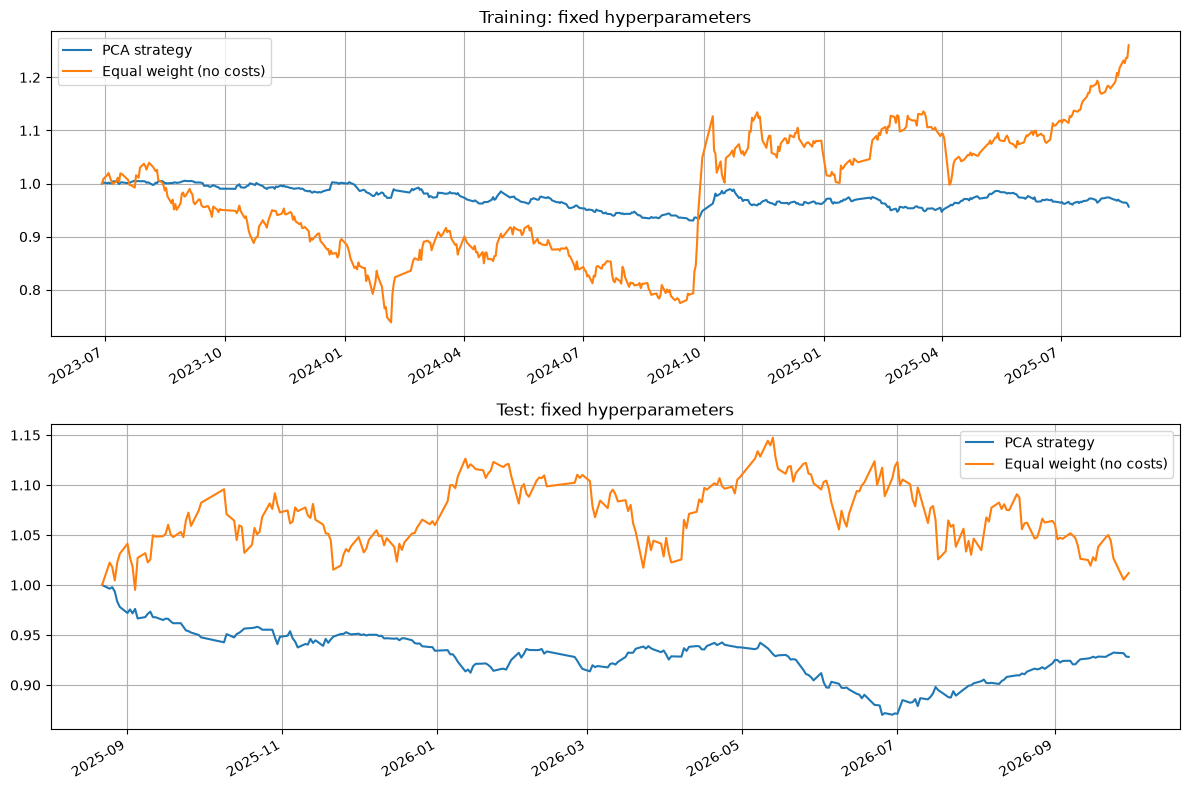

,训练,测试
累计收益,-0.043449,-0.071857
年化夏普,-0.459008,-1.224217
最大回撤,-0.074641,-0.129868
累计换手,118.807762,56.032819
交易费用,0.059404,0.028016


In [11]:
# 上下两个子图分别画训练和测试曲线
fig, axes = plt.subplots(2, 1, figsize=(12, 8))
train_curves.plot(ax=axes[0], title='Training: fixed hyperparameters', grid=True)
test_curves.plot(ax=axes[1], title='Test: fixed hyperparameters', grid=True)
# 自动调整子图间距
plt.tight_layout()
plt.show()
# 把训练和测试指标放在一起对比
metrics = pd.concat({'训练': train_metrics, '测试': test_metrics}, axis=1)
metrics